# Crime and London housing prices: research plan and analysis

**Run the cells from top to bottom.** This notebook works locally or in Google Colab and contains three stages:

1. **Audit the original transactions**: distributions, missingness, geography and crime variation.
2. **Estimate M1–M7**: separate crime categories, common samples and LSOA-clustered uncertainty.
3. **Use monthly MPS records**: validate coverage, merge annual/prior exposure and compare timing.

Use the sidebar table of contents to navigate or collapse sections. The numerical regression engine is under its own heading and must also be run. All other analysis cells have one main task.

**Important:** the supplied violent-crime values are all zero in 2014–2015, and supplied all-crime counts are unusually low in 2010/2015. Baseline estimates remain provisional. The monthly data provide alternative measures; their categories are defined explicitly rather than assumed to replicate the supplied variables.

## 0. Setup

### 0.1 Project folder and input files

In **Google Colab**, the next cell mounts Drive and reads both files directly from `/content/drive/MyDrive/HE3027 Project/data/`. Outputs go to that folder's `crime_outputs/` subfolder.

For **local use**, run from the project folder. Both input files are directly inside `project_data/`, and outputs go to `project_data/crime_outputs/`. No nested input folders or external-data folder are used.


In [35]:
from pathlib import Path

try:
    from google.colab import drive
except ImportError:
    # Local project: both input files are directly inside project_data/.
    ROOT = Path.cwd()
    INPUT_DIR = ROOT / 'project_data'
else:
    # Google Colab: mount Drive before accessing the project files.
    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive/HE3027 Project')
    INPUT_DIR = ROOT / 'data'

DATA = INPUT_DIR / 'land_registry_crime.dta'
MONTHLY_FILE = INPUT_DIR / 'MPS LSOA Level Crime (Historical).csv'
OUT = INPUT_DIR / 'crime_outputs'

for input_file in [DATA, MONTHLY_FILE]:
    if not input_file.is_file():
        raise FileNotFoundError(f'Input file not found: {input_file}')
OUT.mkdir(parents=True, exist_ok=True)

print('Project:', ROOT)
print('Transaction file:', DATA)
print('Monthly file:', MONTHLY_FILE)
print('Outputs:', OUT)


Project: c:\Users\rachm\OneDrive - Nanyang Technological University\Syllabus\Y4S1\HE3027\project
Transaction file: c:\Users\rachm\OneDrive - Nanyang Technological University\Syllabus\Y4S1\HE3027\project\project_data\land_registry_crime.dta
Monthly file: c:\Users\rachm\OneDrive - Nanyang Technological University\Syllabus\Y4S1\HE3027\project\project_data\MPS LSOA Level Crime (Historical).csv
Outputs: c:\Users\rachm\OneDrive - Nanyang Technological University\Syllabus\Y4S1\HE3027\project\project_data\crime_outputs


### 0.2 Import libraries and define table exports

In [36]:
import hashlib
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display
CRIMES = ['allcrime', 'violent_crime', 'propertycrime']
pd.set_option('display.max_columns', 12)
pd.set_option('display.precision', 4)

def table(data, filename):
    """Save the complete table and display a compact preview."""
    data.to_csv(OUT / (filename + '.csv'))
    display(data.head(20) if len(data) > 20 else data)
    if len(data) > 20:
        print(f'Showing 20 of {len(data)} rows; the complete table is saved as {filename}.csv.')

VARIABLE_LABELS = {
    'detached_dum': 'Detached (relative to flat)',
    'semi_d_dum': 'Semi-detached (relative to flat)',
    'terrace_dum': 'Terraced (relative to flat)',
    'freehold': 'Freehold',
    'newbuild': 'New build',
    'tube_distnear_km': 'Distance to tube station (km)',
    'bus_distnear_km': 'Distance to bus stop (km)',
    'thamesriv_dist_km': 'Distance to Thames (km)',
    'Nearest_Park_dist_km': 'Distance to park (km)',
    'dist_to_cbd': 'Distance to CBD (km)',
    'Bus_stopscount_200m': 'Bus stops within 200m',
    'heritage_count_200m': 'Heritage buildings within 200m',
    'percent_noedu': 'Residents without qualifications',
    'percent_minorities': 'Minority residents',
    'lone_hh': 'Lone-parent households',
    'lnpay': 'Log borough annual pay',
    'jobdensity': 'Borough job density',
    'hoursworked': 'Borough weekly hours worked',
    'unemployment': 'Borough unemployment',
}

def coefficient_inference(coefficients, results):
    """Compute inference for every coefficient from its saved clustered SE."""
    keys = [name for name in ['panel', 'model', 'crime', 'measure', 'timing']
            if name in coefficients and name in results]
    metadata = results[keys + ['clusters']]
    enriched = coefficients.drop(columns=['clusters', 't', 'p', 'ci_low', 'ci_high'], errors='ignore')
    enriched = enriched.merge(metadata, on=keys, how='left', validate='many_to_one')
    if enriched.clusters.isna().any():
        raise ValueError('Coefficient rows could not be matched to regression metadata.')
    degrees_freedom = enriched.clusters - 1
    enriched['t'] = enriched.beta / enriched.se
    enriched['p'] = 2 * stats.t.sf(np.abs(enriched.t), degrees_freedom)
    critical = stats.t.ppf(0.975, degrees_freedom)
    enriched['ci_low'] = enriched.beta - critical * enriched.se
    enriched['ci_high'] = enriched.beta + critical * enriched.se
    return enriched

def show_models(results, filename, coefficient_filename):
    """Show one expandable table per model with crime AND control coefficients."""
    from html import escape
    from IPython.display import HTML

    results.to_csv(OUT / (filename + '.csv'), index=False)
    coefficients = coefficient_inference(pd.read_csv(OUT / coefficient_filename), results)
    coefficients.to_csv(OUT / coefficient_filename, index=False)
    cards = []

    def number(value):
        if pd.isna(value):
            return '—'
        if value != 0 and abs(value) < 0.0001:
            return f'{value:.2e}'
        return f'{value:.4f}'

    for _, regression in results.iterrows():
        selected = coefficients.model.eq(regression['model'])
        for key in ['panel', 'crime', 'measure', 'timing']:
            if key in coefficients and key in results:
                selected &= coefficients[key].eq(regression[key])
        rows = coefficients.loc[selected].copy()
        title = regression['model'] + ' · ' + str(regression.get('crime', regression.get('measure', '')))
        if 'timing' in results:
            title += ' · ' + regression['timing']
        rendered = []
        for _, row in rows.iterrows():
            label = VARIABLE_LABELS.get(row.variable, row.variable)
            if row.variable.startswith('log1p_'):
                label = 'Crime: log(1 + ' + row.variable[6:].replace('_', ' ') + ')'
            rendered.append({
                'Variable': label,
                'Coefficient': number(row.beta),
                'Clustered SE': number(row.se),
                't statistic': f'{row.t:.2f}',
                '95% CI': number(row.ci_low) + ' to ' + number(row.ci_high),
                'p-value': '<0.001' if row.p < 0.001 else f'{row.p:.3f}',
            })
        effects = regression.get('fixed_effects', '')
        effects = 'None' if pd.isna(effects) or not effects else str(effects)
        r2_label = 'Within R²' if regression.r2_type == 'within' else 'R²'
        subtitle = (f'N = {int(regression.N):,} | LSOA clusters = {int(regression.clusters):,}'
                    f' | {r2_label} = {regression.r2:.4f}')
        body = pd.DataFrame(rendered).to_html(index=False, border=0, escape=True)
        omitted = regression.get('absorbed_or_collinear', '')
        note = '' if pd.isna(omitted) or not omitted else '<p>Absorbed/collinear: ' + escape(str(omitted)) + '</p>'
        cards.append('<details class="reg-card"><summary>' + escape(title) + '</summary>'
                     '<p>' + escape(subtitle) + '</p><p>Fixed effects: ' + escape(effects) + '</p>'
                     + body + note + '</details>')
    style = '<style>.reg-card{margin:10px 0;padding:12px;border:1px solid #bbb;border-radius:6px;overflow-x:auto}.reg-card summary{cursor:pointer;font-weight:600}.reg-card table{border-collapse:collapse;width:100%;max-width:950px}.reg-card th,.reg-card td{padding:7px 10px;border-bottom:1px solid #ddd;text-align:right;white-space:nowrap}.reg-card th:first-child,.reg-card td:first-child{text-align:left}.reg-card p{font-size:13px}</style>'
    display(HTML(style + '<p>Expand a regression to view all estimated coefficients. Standard errors are clustered by LSOA.</p>' + ''.join(cards)))
    return coefficients


### 0.3 Load the original data

In [37]:
df = pd.read_stata(DATA, convert_categoricals=False)
df['transaction_id'] = np.arange(len(df))
with pd.io.stata.StataReader(DATA) as reader:
    labels = reader.variable_labels()
print(f'{len(df):,} transactions and {len(labels)} original variables')
print('Dates:', df.transactiondates.min(), 'to', df.transactiondates.max())
pd.Series(labels, name='stata_label').to_csv(OUT / 'variable_labels.csv')
pd.Series({'data_sha256': hashlib.sha256(DATA.read_bytes()).hexdigest(), 'pandas': pd.__version__, 'numpy': np.__version__}).to_csv(OUT / 'provenance.csv')

549,813 transactions and 50 original variables
Dates: 2010-01-01 00:00:00 to 2015-07-30 00:00:00


## 1. Audit and descriptive statistics

### 1.1 Variable definitions and missing values

`age` is new-build status, not actual building age. `hectares` and `totalpopulation` are borough measures and cannot be used as LSOA denominators. Full tables are saved even when only their first 20 rows are displayed.

In [38]:
schema = pd.DataFrame({'dtype': df.dtypes.astype(str), 'missing': df.isna().sum(), 'blank_strings': [df[c].eq('').sum() if df[c].dtype.kind in 'OU' else 0 for c in df], 'unique': df.nunique()})
schema['missing_pct'] = 100 * schema['missing'] / len(df)
table(schema.join(pd.Series(labels, name='label')), 'schema')

,dtype,missing,blank_strings,unique,missing_pct,label
price,int32,0,0,20016,0.0000,Sale price stated on the transfer deed
postalcode,str,0,0,107460,0.0000,Postalcode
propertyty,str,0,0,4,0.0000,"D = Detached, S = Semi-Detached, T = Terraced,..."
age,str,0,0,2,0.0000,Y= newly built ; N = established residential b...
duration,str,0,0,2,0.0000,"F = Freehold, L= Leasehold etc. Note that Land..."
year,int16,0,0,6,0.0000,Year Property was sold
month,int8,0,0,12,0.0000,Month Property was sold
day,int8,0,0,31,0.0000,
OA01CD,str,0,0,23806,0.0000,
OA11CD,str,0,0,24697,0.0000,Output Area (OA) Code 2011


Showing 20 of 51 rows; the complete table is saved as schema.csv.


### 1.2 Price and crime distributions

In [39]:
table(df[['price'] + CRIMES].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T, 'transaction_descriptives')

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
price,549813.0,463444.2778,607860.5786,10000.0,108000.0,150000.0,235000.0,322450.0,490000.0,1180000.0,2.6547e+06,5.4959e+07
allcrime,549813.0,182.6549,315.0519,1.0,3.0,6.0,43.0,123.0,216.0,520.0,1.2720e+03,9.2250e+03
violent_crime,549813.0,12.0190,26.7323,0.0,0.0,0.0,0.0,4.0,15.0,47.0,1.0088e+02,1.0980e+03
propertycrime,549813.0,22.7628,21.5091,0.0,0.0,0.0,6.0,21.0,32.0,56.0,9.1000e+01,3.8900e+02


### 1.3 Geography and consistency checks

In [40]:
table(df.groupby('la_name').agg(transactions=('price', 'size'), lsoas=('lsoacode', 'nunique')), 'geographical_coverage')
checks = pd.Series({'nonpositive_prices': int(df.price.le(0).sum()), 'duplicate_full_original_rows': int(df.drop(columns='transaction_id').duplicated().sum()), 'date_year_mismatches': int(df.transactiondates.dt.year.ne(df.year).sum()), 'date_month_mismatches': int(df.transactiondates.dt.month.ne(df.month).sum()), 'lsoas_in_multiple_msoas': int(df.groupby('lsoacode').msoa11.nunique().gt(1).sum()), 'lsoas_in_multiple_authorities': int(df.groupby('lsoacode').oslaua.nunique().gt(1).sum())})
table(checks.to_frame('count'), 'audit_checks')
print('Duplicate rows are flagged, not automatically removed: addresses are unavailable.')

,transactions,lsoas
la_name,,
Barking and Dagenham,9080,110
Barnet,23699,211
Bexley,16683,146
Brent,12985,173
Bromley,27399,197
Camden,14419,133
City of London,1583,6
Croydon,23731,220
Ealing,18036,197


Showing 20 of 38 rows; the complete table is saved as geographical_coverage.csv.


,count
nonpositive_prices,0
duplicate_full_original_rows,2894
date_year_mismatches,0
date_month_mismatches,0
lsoas_in_multiple_msoas,0
lsoas_in_multiple_authorities,3


Duplicate rows are flagged, not automatically removed: addresses are unavailable.


### 1.4 Missing economic controls and zero crime counts

In [41]:
table(df.groupby('year')[['jobdensity', 'grossannualpay', 'unemployment']].agg(lambda x: x.isna().mean()), 'economic_missingness_by_year')
table(pd.DataFrame({'zero_share': df[CRIMES].eq(0).mean(), 'negative_count': df[CRIMES].lt(0).sum()}), 'crime_zeros')

,jobdensity,grossannualpay,unemployment
year,,,
2010,0.0,0.000,0.0026
2011,0.0,0.000,0.0029
2012,0.0,0.000,0.0021
2013,0.0,0.026,0.0039
2014,0.0,0.000,0.0026
2015,1.0,0.000,0.0033


,zero_share,negative_count
allcrime,0.0000,0
violent_crime,0.3516,0
propertycrime,0.0631,0


### 1.5 Crime by LSOA-year

Use one record per LSOA-year to avoid giving high-transaction areas greater weight. Check that the supplied crime count is constant within each LSOA-year before taking its first value.

In [42]:
crime_constancy = df.groupby(['lsoacode', 'year'])[CRIMES].nunique()
assert not crime_constancy.gt(1).any().any(), 'Crime varies within LSOA-year: inspect before modelling.'
area_year = df.groupby(['lsoacode', 'year'], as_index=False)[CRIMES].first()
table(area_year[CRIMES].describe().T, 'lsoa_year_crime_descriptives')
table(area_year.groupby('year')[CRIMES].agg(['mean', 'median', lambda s: s.eq(0).mean()]), 'crime_by_year_with_zero_shares')
print('SOURCE VALIDATION WARNING: crime means are much lower in 2010 and 2015;')
print('violent crime is zero throughout the observed 2014 and 2015 LSOA-years.')
print('Do not infer full-year comparability or interpret these zeros as validated absence of violence.')

,count,mean,std,min,25%,50%,75%,max
allcrime,28858.0,154.3839,258.5377,1.0,20.0,108.0,199.0,9225.0
violent_crime,28858.0,11.6884,23.4100,0.0,0.0,3.0,15.0,1098.0
propertycrime,28858.0,19.7013,19.2776,0.0,3.0,18.0,30.0,389.0


allcrime                   violent_crime                    \
          mean median <lambda_0>          mean median <lambda_0>   
year                                                               
2010   19.3462   14.0        0.0        2.4603    2.0     0.2412   
2011  255.0868  186.0        0.0       30.8135   23.0     0.0015   
2012  233.6485  172.0        0.0       28.1486   22.0     0.0010   
2013  205.8616  150.0        0.0        8.6017    7.0     0.0286   
2014  195.1985  142.0        0.0        0.0000    0.0     1.0000   
2015   15.1133   11.0        0.0        0.0000    0.0     1.0000   

     propertycrime                    
              mean median <lambda_0>  
year                                  
2010        1.6447    1.0     0.2870  
2011       24.5559   22.0     0.0008  
2012       32.1349   29.0     0.0002  
2013       29.6725   26.0     0.0008  
2014       27.5974   24.0     0.0002  
2015        2.3272    2.0     0.1701

SOURCE VALIDATION WARNING: crime means are much lower in 2010 and 2015;
violent crime is zero throughout the observed 2014 and 2015 LSOA-years.
Do not infer full-year comparability or interpret these zeros as validated absence of violence.


### 1.6 Is there enough within-LSOA variation?

In [43]:
variation = []
for c in CRIMES:
    g = area_year.groupby('lsoacode')[c]
    within = area_year[c] - g.transform('mean')
    variation.append({'crime': c, 'lsoas': g.ngroups, 'lsoas_varying': int(g.nunique().gt(1).sum()), 'between_lsoa_sd': g.mean().std(), 'within_lsoa_sd': within.std(), 'median_lsoa_range': (g.max() - g.min()).median()})
table(pd.DataFrame(variation), 'crime_variation')
table(area_year.groupby('lsoacode').size().value_counts().sort_index().to_frame('lsoas'), 'years_observed_per_lsoa')

,crime,lsoas,lsoas_varying,between_lsoa_sd,within_lsoa_sd,median_lsoa_range
0,allcrime,4836,4832,198.6720,165.0906,196.0
1,violent_crime,4836,4830,12.6386,19.7034,26.0
2,propertycrime,4836,4832,11.1102,15.7562,33.0


,lsoas
1,4
2,4
3,4
4,14
5,82
6,4728


### 1.7 At what geographical level do controls vary?

In [44]:
audit_vars = ['percent_noedu', 'percent_minorities', 'lone_hh', 'tube_distnear', 'bus_distnear', 'Nearest_Park_dist', 'hectares', 'totalpopulation', 'grossannualpay', 'jobdensity', 'hoursworked', 'unemployment']
table(pd.DataFrame({'lsoas_with_multiple_values': df.groupby('lsoacode')[audit_vars].nunique().gt(1).sum(), 'max_values_within_authority_year': df.groupby(['oslaua', 'year'])[audit_vars].nunique().max()}), 'control_variation_levels')

,lsoas_with_multiple_values,max_values_within_authority_year
percent_noedu,4829,944
percent_minorities,4829,1039
lone_hh,4828,750
tube_distnear,4829,3182
bus_distnear,4829,2851
Nearest_Park_dist,4829,3182
hectares,3,1
totalpopulation,4832,1
grossannualpay,4832,1
jobdensity,4830,1


### 1.8 Transaction composition over time

In [45]:
yearly = df.groupby('year').agg(N=('price', 'size'), median_price=('price', 'median'), flat_share=('flat_dum', 'mean'), freehold_share=('freehold', 'mean'), newbuild_share=('age', lambda x: x.eq('Y').mean()))
table(yearly, 'annual_transaction_composition')
table(pd.crosstab(df.year, df.propertyty, normalize='index'), 'property_mix_by_year')

,N,median_price,flat_share,freehold_share,newbuild_share
year,,,,,
2010,91085,286000.0,0.5102,0.4809,0.0811
2011,89499,291000.0,0.5034,0.4845,0.0730
2012,91980,300000.0,0.5227,0.4667,0.0995
2013,110733,323000.0,0.5394,0.4502,0.0983
2014,117519,365000.0,0.5590,0.4304,0.0958
2015,48997,388000.0,0.5265,0.4636,0.0735


propertyty,D,F,S,T
year,,,,
2010,0.0495,0.5102,0.1580,0.2824
2011,0.0507,0.5034,0.1591,0.2868
2012,0.0477,0.5227,0.1489,0.2807
2013,0.0487,0.5394,0.1426,0.2693
2014,0.0478,0.5590,0.1318,0.2614
2015,0.0485,0.5265,0.1437,0.2813


### 1.9 Descriptive figures

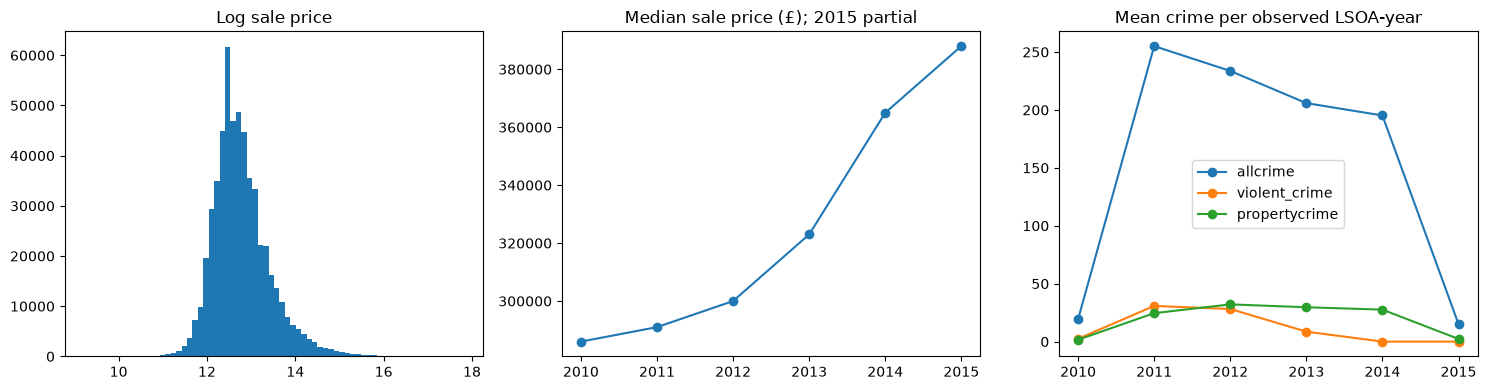

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(np.log(df.loc[df.price.gt(0), 'price']), bins=70)
axes[0].set_title('Log sale price')
axes[1].plot(yearly.index, yearly.median_price, marker='o')
axes[1].set_title('Median sale price (£); 2015 partial')
for c in CRIMES:
    t = area_year.groupby('year')[c].mean()
    axes[2].plot(t.index, t, label=c, marker='o')
axes[2].set_title('Mean crime per observed LSOA-year')
axes[2].legend()
fig.tight_layout()
fig.savefig(OUT / 'audit_trends.png', dpi=160)
plt.show()

## 2. Sequential regressions on the supplied data

### 2.1 Create model variables

`log1p(crime)` is `log(1 + crime)`, retaining zero counts. Its coefficient is not exactly an elasticity. Distances recorded in metres are expressed in kilometres; CBD distance already uses kilometres. No supplied suspicious zeros are silently repaired.

In [47]:
df['lnprice'] = np.log(df.price.where(df.price.gt(0)))
df['newbuild'] = df.age.eq('Y').astype(float)
df['borough_year'] = df.oslaua + '_' + df.year.astype(str)
for c in CRIMES:
    assert df[c].ge(0).all()
    df['log1p_' + c] = np.log1p(df[c])
for c in ['tube_distnear', 'bus_distnear', 'thamesriv_dist', 'Nearest_Park_dist']:
    df[c + '_km'] = df[c] / 1000
df['lnpay'] = np.log(df.grossannualpay.where(df.grossannualpay.gt(0)))
PROPERTY = ['detached_dum', 'semi_d_dum', 'terrace_dum', 'freehold', 'newbuild']
AMENITY = ['tube_distnear_km', 'bus_distnear_km', 'thamesriv_dist_km', 'Nearest_Park_dist_km', 'dist_to_cbd', 'Bus_stopscount_200m', 'heritage_count_200m']
SOCIAL = ['percent_noedu', 'percent_minorities', 'lone_hh']
ECONOMIC = ['lnpay', 'jobdensity', 'hoursworked', 'unemployment']

### 2.2 Define M1–M7 in one place

| Model | Explicit controls | Fixed effects |
|---|---|---|
| M1 | Crime only | None |
| M2 | + property characteristics | None |
| M3 | + amenities and accessibility | None |
| M4 | + social and economic conditions | None |
| M5 | Same as M4 | MSOA + year-quarter |
| M6 | Same as M4 | LSOA + year-quarter |
| M7 | Property + amenities + social | LSOA + year-quarter + borough-year |

**Why does M7 list fewer controls?** Pay, job density, hours and unemployment are constant within borough-year. Borough-year effects absorb them, so their separate coefficients are not identifiable. M7 controls for additional borough-year variation despite listing fewer explicit variables.

In [48]:
def specifications(include_jobdensity=True):
    economic_controls = [name for name in ECONOMIC if include_jobdensity or name != 'jobdensity']
    property_controls = PROPERTY
    property_amenity_controls = PROPERTY + AMENITY
    full_controls = property_amenity_controls + SOCIAL + economic_controls
    return [('M1', [], []), ('M2', property_controls, []), ('M3', property_amenity_controls, []), ('M4', full_controls, []), ('M5', full_controls, ['msoa11', 'yearquarter']), ('M6', full_controls, ['lsoacode', 'yearquarter']), ('M7', property_amenity_controls + SOCIAL, ['lsoacode', 'yearquarter', 'borough_year'])]

### 2.3 Regression engine — run these two cells once

The engine absorbs fixed effects without allocating thousands of dummy columns. Its implementation is shown in the two code cells below. It checks convergence and collinearity. Inference clusters by LSOA using G/(G−1) and a t(G−1) reference distribution, without an additional correction for absorbed degrees of freedom. Within R² in fixed-effect models is not comparable to ordinary R² in M1–M4.

In [49]:
def absorb(matrix, groups, tol=1e-10, max_iter=2000):
    z = np.asarray(matrix, dtype=float).copy()
    codes = [pd.factorize(g, sort=False)[0] for g in groups]
    if any(((g < 0).any() for g in codes)):
        raise ValueError('Missing fixed-effect ID')
    for iteration in range(max_iter):
        before = z.copy()
        for g in codes:
            counts = np.bincount(g)
            sums = np.column_stack([np.bincount(g, weights=z[:, j], minlength=len(counts)) for j in range(z.shape[1])])
            z -= (sums / counts[:, None])[g]
        if np.max(np.abs(z - before)) < tol:
            return (z, iteration + 1)
    raise RuntimeError('Fixed-effect absorption did not converge')

In [50]:
def fit_absorbed(data, crime, controls, fixed_effects, cluster='lsoacode'):
    names = [crime] + controls
    x = data[names].to_numpy(dtype=float, copy=True)
    scale = x.std(axis=0)
    scale[scale < 1e-14] = 1
    x /= scale
    y = data.lnprice.to_numpy(float)
    if fixed_effects:
        z, iterations = absorb(np.column_stack([y, x]), [data[c] for c in fixed_effects])
        y, x = (z[:, 0], z[:, 1:])
    else:
        y = y - y.mean()
        x = x - x.mean(axis=0)
        iterations = 0
    gram = x.T @ x
    keep = []
    for j in range(x.shape[1]):
        residual_norm2 = gram[j, j]
        if keep:
            cross = gram[keep, j]
            residual_norm2 -= cross @ np.linalg.solve(gram[np.ix_(keep, keep)], cross)
        if residual_norm2 > 1e-10 * len(data):
            keep.append(j)
    if 0 not in keep:
        raise ValueError('Crime has no identifying variation in this specification')
    design = x[:, keep]
    beta = np.linalg.lstsq(design, y, rcond=None)[0]
    residual = y - design @ beta
    group = pd.factorize(data[cluster], sort=False)[0]
    G = group.max() + 1
    if G < 2:
        raise ValueError('Need multiple inference clusters')
    scores = np.zeros((G, len(keep)))
    for j in range(len(keep)):
        scores[:, j] = np.bincount(group, weights=design[:, j] * residual, minlength=G)
    bread = np.linalg.inv(design.T @ design)
    covariance = bread @ (scores.T @ scores) @ bread * G / (G - 1)
    estimates = beta / scale[keep]
    se = np.sqrt(np.maximum(np.diag(covariance), 0)) / scale[keep]
    j = keep.index(0)
    critical = stats.t.ppf(0.975, G - 1)
    result = {'N': len(data), 'clusters': G, 'beta': estimates[j], 'se': se[j], 'p': 2 * stats.t.sf(abs(estimates[j] / se[j]), G - 1), 'ci_low': estimates[j] - critical * se[j], 'ci_high': estimates[j] + critical * se[j], 'r2': 1 - residual @ residual / (y @ y), 'r2_type': 'within' if fixed_effects else 'ordinary', 'crime_residual_sd': x[:, 0].std() * scale[0], 'iterations': iterations, 'absorbed_or_collinear': '; '.join((names[j] for j in range(len(names)) if j not in keep)), 'fixed_effects': '; '.join(fixed_effects)}
    coefficients = pd.DataFrame({'variable': [names[j] for j in keep], 'beta': estimates, 'se': se})
    return (result, coefficients)

### 2.4 Define common samples

The strict panel includes job density and consequently excludes 2015. The expanded panel excludes job density and retains eligible 2015 sales. Both exclude non-London observations and LSOAs assigned to multiple London boroughs. All models and crime categories within a panel use the same sample.

In [51]:
def common_sample(data, include_jobdensity=True, crime_cols=None):
    crime_cols = crime_cols or ['log1p_' + c for c in CRIMES]
    needed = set(['lnprice', 'lsoacode', 'msoa11', 'yearquarter', 'borough_year'] + crime_cols)
    for _, controls, _ in specifications(include_jobdensity):
        needed.update(controls)
    valid = data[list(needed)].replace('', np.nan).notna().all(axis=1)
    valid &= np.isfinite(data[list(needed)].select_dtypes(include='number')).all(axis=1)
    valid &= data.oslaua.str.startswith('E090')
    london = data.loc[data.oslaua.str.startswith('E090')]
    borough_count = london.groupby('lsoacode').oslaua.nunique()
    ambiguous = borough_count.index[borough_count.gt(1)]
    valid &= ~data.lsoacode.isin(ambiguous)
    return data.loc[valid].copy()

In [52]:
strict = common_sample(df, True)
expanded = common_sample(df, False)
sample_audit = pd.DataFrame({'original': df.groupby('year').size(), 'strict_with_jobdensity': strict.groupby('year').size(), 'without_jobdensity': expanded.groupby('year').size()}).fillna(0).astype(int)
table(sample_audit, 'common_sample_by_year')
geo = df.loc[df.oslaua.str.startswith('E090')]
conflicts = geo.groupby('lsoacode').oslaua.nunique()
table(geo.loc[geo.lsoacode.isin(conflicts.index[conflicts.gt(1)])].groupby(['lsoacode', 'la_name']).size().to_frame('N'), 'excluded_conflicting_lsoa_borough_assignments')

,original,strict_with_jobdensity,without_jobdensity
year,,,
2010,91085,90825,90825
2011,89499,89203,89203
2012,91980,91744,91744
2013,110733,107378,107378
2014,117519,117169,117169
2015,48997,0,48822


N
lsoacode  la_name      
E01000804 Bromley   110
          Lewisham    9
E01002564 Ealing      2
          Hounslow   85

### 2.5 Define the sequence runner

In [53]:
def run_sequence(sample, panel, include_jobdensity=True):
    rows, allcoef = ([], [])
    for model, controls, effects in specifications(include_jobdensity):
        pass  # Model details are shown in the formatted output below.
        prepared = sample
        projection_iterations = 0
        if effects:
            columns = ['lnprice'] + ['log1p_' + c for c in CRIMES] + controls
            matrix = sample[columns].to_numpy(dtype=float, copy=True)
            scales = matrix.std(axis=0)
            scales[scales < 1e-14] = 1
            matrix, projection_iterations = absorb(matrix / scales, [sample[c] for c in effects])
            prepared = sample.copy()
            prepared[columns] = matrix * scales
        for category in CRIMES:
            r, b = fit_absorbed(prepared, 'log1p_' + category, controls, [])
            if effects:
                r.update(r2_type='within', fixed_effects='; '.join(effects), iterations=projection_iterations)
            rows.append(dict(panel=panel, model=model, crime=category, **r))
            allcoef.append(b.assign(panel=panel, model=model, crime=category))
            pd.DataFrame(rows).to_csv(OUT / (panel + '_models.csv'), index=False)
    results = pd.DataFrame(rows)
    results.to_csv(OUT / (panel + '_models.csv'), index=False)
    pd.concat(allcoef).to_csv(OUT / (panel + '_all_coefficients.csv'), index=False)
    return results

### 2.6 Estimate the strict panel

In [54]:
strict_results = run_sequence(strict, 'strict', True)
strict_coefficients = show_models(strict_results, 'strict_results_display', 'strict_all_coefficients.csv')

Variable,Coefficient,Clustered SE,t statistic,95% CI,p-value
Crime: log(1 + allcrime),0.0193,0.0048,3.99,0.0098 to 0.0288,<0.001
Variable,Coefficient,Clustered SE,t statistic,95% CI,p-value
Crime: log(1 + violent crime),-0.0641,0.0026,-24.67,-0.0692 to -0.0590,<0.001
Variable,Coefficient,Clustered SE,t statistic,95% CI,p-value
Crime: log(1 + propertycrime),0.0249,0.0037,6.80,0.0177 to 0.0321,<0.001
Variable,Coefficient,Clustered SE,t statistic,95% CI,p-value
Crime: log(1 + allcrime),0.0448,0.0048,9.28,0.0354 to 0.0543,<0.001
Detached (relative to flat),0.6293,0.0233,27.04,0.5837 to 0.6749,<0.001
Semi-detached (relative to flat),0.1559,0.0185,8.43,0.1196 to 0.1921,<0.001
Terraced (relative to flat),0.1138,0.0177,6.44,0.0791 to 0.1484,<0.001


### 2.7 Estimate the expanded panel

In [55]:
expanded_results = run_sequence(expanded, 'without_jobdensity', False)
expanded_coefficients = show_models(expanded_results, 'expanded_results_display', 'without_jobdensity_all_coefficients.csv')

Variable,Coefficient,Clustered SE,t statistic,95% CI,p-value
Crime: log(1 + allcrime),-0.0051,0.0040,-1.28,-0.0130 to 0.0027,0.201
Variable,Coefficient,Clustered SE,t statistic,95% CI,p-value
Crime: log(1 + violent crime),-0.0692,0.0023,-29.54,-0.0738 to -0.0646,<0.001
Variable,Coefficient,Clustered SE,t statistic,95% CI,p-value
Crime: log(1 + propertycrime),0.0003,0.0031,0.10,-0.0058 to 0.0064,0.922
Variable,Coefficient,Clustered SE,t statistic,95% CI,p-value
Crime: log(1 + allcrime),0.0147,0.0040,3.71,0.0069 to 0.0224,<0.001
Detached (relative to flat),0.6144,0.0231,26.65,0.5692 to 0.6596,<0.001
Semi-detached (relative to flat),0.1500,0.0182,8.23,0.1143 to 0.1858,<0.001
Terraced (relative to flat),0.1158,0.0174,6.66,0.0817 to 0.1499,<0.001


### 2.8 Compare coefficients across specifications

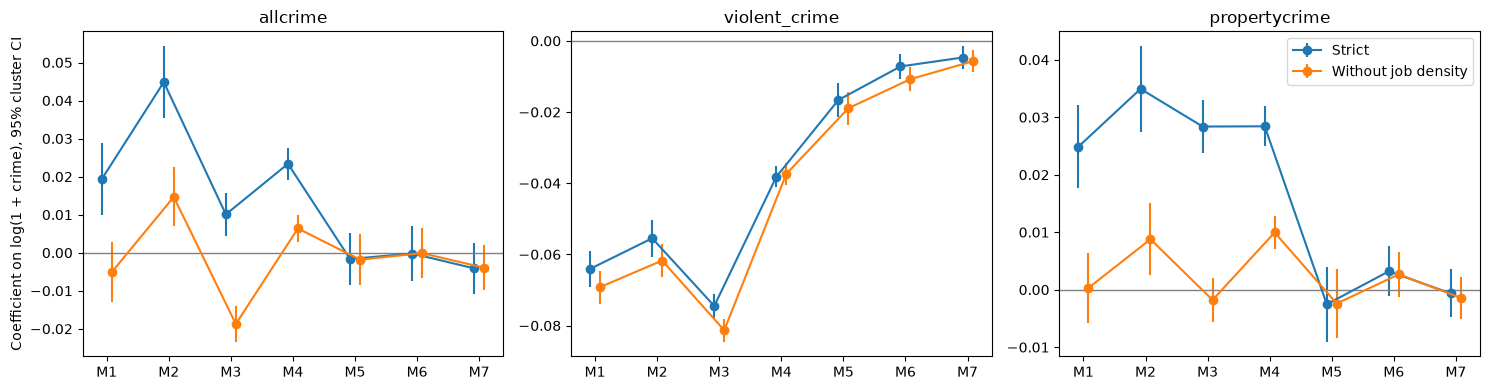

In [57]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True)
for ax, category in zip(axes, CRIMES):
    for panel, results, offset in [('Strict', strict_results, -0.08), ('Without job density', expanded_results, 0.08)]:
        r = results.loc[results.crime.eq(category)]
        ax.errorbar(np.arange(1, 8) + offset, r.beta, yerr=np.vstack([r.beta - r.ci_low, r.ci_high - r.beta]), fmt='o-', label=panel)
    ax.axhline(0, color='grey', linewidth=1)
    ax.set_title(category)
    ax.set_xticks(range(1, 8), ['M' + str(i) for i in range(1, 8)])
axes[0].set_ylabel('Coefficient on log(1 + crime), 95% cluster CI')
axes[-1].legend()
fig.tight_layout()
fig.savefig(OUT / 'sequential_crime_coefficients.png', dpi=160)
plt.show()

## 3. Monthly crime merge and prior exposure

### 3.1 Read the monthly source

This section uses the file you added. Monthly columns must be sorted by date because the CSV header is not chronological. It covers April 2010 onward; full prior-year exposure first exists for April 2011 sales. Annual 2010 totals are left missing because January–March are absent.

In [58]:
if MONTHLY_FILE is None:
    raise FileNotFoundError('Stage 3 needs MPS LSOA Level Crime (Historical).csv in the project folder or project_data/.')
MPS = MONTHLY_FILE
raw = pd.read_csv(MPS, encoding='utf-8-sig')
raw.columns = raw.columns.str.strip()
print('Monthly file:', MPS)
print('SHA256:', hashlib.sha256(MPS.read_bytes()).hexdigest())
print('Category rows:', len(raw))

Monthly file: c:\Users\rachm\OneDrive - Nanyang Technological University\Syllabus\Y4S1\HE3027\project\project_data\MPS LSOA Level Crime (Historical).csv
SHA256: 9849c110ebb69c0c518126c09a60aa6f7fa5f5294ce22b28628c2e04c24de4fa
Category rows: 112977


### 3.2 Validate monthly coverage and source categories

In [59]:
required = ['LSOA Code', 'Borough', 'Major Category', 'Minor Category']
assert set(required) <= set(raw.columns)
assert not raw.duplicated(['LSOA Code', 'Major Category', 'Minor Category']).any()
assert not raw[required].isna().any().any()
assert raw.groupby('LSOA Code').Borough.nunique().max() == 1
month_cols = sorted((c for c in raw if re.fullmatch('20\\d{2}(0[1-9]|1[0-2])', c)))
study_months = [c for c in month_cols if '201004' <= c <= '201512']
expected = pd.period_range('2010-04', '2015-12', freq='M').strftime('%Y%m').tolist()
assert study_months == expected, 'Missing study months: ' + str(set(expected) - set(study_months))
counts = raw[study_months].apply(pd.to_numeric, errors='raise')
assert counts.notna().all().all(), 'Inspect missing monthly cells before aggregation'
assert counts.ge(0).all().all() and (counts % 1).eq(0).all().all()
print('Source coverage:', month_cols[0], month_cols[-1], '; study months:', len(study_months))
table(raw.groupby('Major Category').agg(rows=('LSOA Code', 'size'), lsoas=('LSOA Code', 'nunique')), 'source_categories')
table(raw[['Major Category', 'Minor Category']].drop_duplicates().sort_values(['Major Category', 'Minor Category']), 'source_minor_categories')

Source coverage: 201004 202211 ; study months: 69


,rows,lsoas
Major Category,,
ARSON AND CRIMINAL DAMAGE,9543,4988
BURGLARY,9974,4988
DRUG OFFENCES,9834,4988
MISCELLANEOUS CRIMES AGAINST SOCIETY,4983,4983
POSSESSION OF WEAPONS,4875,4875
PUBLIC ORDER OFFENCES,15504,4988
ROBBERY,9028,4983
THEFT,19026,4988
VEHICLE OFFENCES,19045,4988


,Major Category,Minor Category
0,ARSON AND CRIMINAL DAMAGE,ARSON
1,ARSON AND CRIMINAL DAMAGE,CRIMINAL DAMAGE
2,BURGLARY,BURGLARY BUSINESS AND COMMUNITY
3,BURGLARY,BURGLARY IN A DWELLING
4,DRUG OFFENCES,POSSESSION OF DRUGS
5,DRUG OFFENCES,TRAFFICKING OF DRUGS
6,MISCELLANEOUS CRIMES AGAINST SOCIETY,MISC CRIMES AGAINST SOCIETY
7,POSSESSION OF WEAPONS,POSSESSION OF WEAPONS
8,PUBLIC ORDER OFFENCES,OTHER OFFENCES PUBLIC ORDER
9,PUBLIC ORDER OFFENCES,PUBLIC FEAR ALARM OR DISTRESS


Showing 20 of 25 rows; the complete table is saved as source_minor_categories.csv.


### 3.3 Construct the monthly crime groups

| Measure | Definition |
|---|---|
| `mps_all` | All offences published in this file |
| `mps_violence` | Violence Against the Person |
| `mps_property` | Burglary + Theft + Vehicle Offences + Arson and Criminal Damage |
| `mps_residential_burglary` | Burglary in a Dwelling |

These groups are not assumed to equal the supplied crime definitions. Sexual offences are absent from this file. Robbery is not included in the property group. Missing category groups remain missing.

In [60]:
GROUPS = {'mps_all': None, 'mps_violence': ['VIOLENCE AGAINST THE PERSON'], 'mps_property': ['BURGLARY', 'THEFT', 'VEHICLE OFFENCES', 'ARSON AND CRIMINAL DAMAGE']}
series = {}
for name, categories in GROUPS.items():
    subset = raw if categories is None else raw.loc[raw['Major Category'].isin(categories)]
    wide = subset.groupby('LSOA Code')[study_months].sum(min_count=1)
    if categories is not None:
        complete = subset.groupby('LSOA Code')['Major Category'].nunique().eq(len(categories))
        wide = wide.where(complete, axis=0)
    series[name] = wide
series['mps_residential_burglary'] = raw.loc[raw['Minor Category'].eq('BURGLARY IN A DWELLING')].groupby('LSOA Code')[study_months].sum(min_count=1)
monthly_parts = []
for name, wide in series.items():
    long = wide.reset_index().melt(id_vars='LSOA Code', var_name='month_text', value_name=name)
    long['month'] = pd.to_datetime(long.pop('month_text'), format='%Y%m').dt.to_period('M')
    long = long.rename(columns={'LSOA Code': 'lsoacode'}).set_index(['lsoacode', 'month'])
    monthly_parts.append(long)
monthly = pd.concat(monthly_parts, axis=1).sort_index()
MEASURES = list(series)
table(monthly.groupby(level='month')[MEASURES].sum(min_count=1), 'monthly_source_totals')
monthly.reset_index().to_csv(OUT / 'lsoa_month_crime.csv.gz', index=False, compression={'method': 'gzip', 'compresslevel': 1})

,mps_all,mps_violence,mps_property,mps_residential_burglary
month,,,,
2010-04,64053,11648,42093,4307
2010-05,65951,12657,42334,4385
2010-06,66686,12830,43317,4380
2010-07,67704,12934,43497,4442
2010-08,62821,11251,40534,4517
2010-09,63553,11228,41953,4725
2010-10,66031,11332,43750,5057
2010-11,64530,10578,43700,6008
2010-12,54913,9959,36646,5523


Showing 20 of 69 rows; the complete table is saved as monthly_source_totals.csv.


### 3.4 Build exposure and check the geographical merge

Prior exposure excludes the sale month and requires twelve complete months. Match exact LSOA codes only. City of London and transactions whose borough differs from the source borough have missing external exposure. City of London is excluded because it has its own police force. We should not assume a Metropolitan Police dataset provides complete crime coverage there. Missing MPS coverage must not be interpreted as zero crime. Every original transaction is retained in the merged export.

In [61]:
grid = pd.MultiIndex.from_product([monthly.index.get_level_values('lsoacode').unique(), pd.period_range('2010-04', '2015-12', freq='M')], names=['lsoacode', 'month'])
monthly = monthly.reindex(grid)
exposure = monthly.copy()
for c in MEASURES:
    exposure[c + '_prior12'] = monthly.groupby(level='lsoacode')[c].transform(lambda s: s.shift(1).rolling(12, min_periods=12).sum())
exposure = exposure.reset_index().rename(columns={'month': 'sale_month'})
borough = raw[['LSOA Code', 'Borough']].drop_duplicates().rename(columns={'LSOA Code': 'lsoacode', 'Borough': 'mps_borough'})
df['sale_month'] = df.transactiondates.dt.to_period('M')
merged = df.merge(borough, on='lsoacode', how='left', validate='many_to_one')
merged = merged.merge(exposure, on=['lsoacode', 'sale_month'], how='left', validate='many_to_one', indicator='monthly_merge')
merged['mps_code_match'] = merged.lsoacode.isin(borough.lsoacode)
merged['mps_sale_month_match'] = merged.monthly_merge.eq('both')
merged['mps_borough_match'] = merged.oslaua.eq(merged.mps_borough)
merged['city_of_london'] = merged.oslaua.eq('E09000001')
merged['mps_geography_ok'] = merged.mps_code_match & merged.mps_borough_match & ~merged.city_of_london

### 3.5 Add complete annual counts and export the merged dataset

In [62]:
a = monthly.reset_index()
a['year'] = a.month.dt.year
group = a.groupby(['lsoacode', 'year'])
annual = group[MEASURES].sum(min_count=12).where(group[MEASURES].count().eq(12))
annual = annual.rename(columns={c: c + '_annual' for c in MEASURES}).reset_index()
merged = merged.merge(annual, on=['lsoacode', 'year'], how='left', validate='many_to_one')
external_columns = MEASURES + [c + '_prior12' for c in MEASURES] + [c + '_annual' for c in MEASURES]
merged.loc[~merged.mps_geography_ok, external_columns] = np.nan
assert len(merged) == len(df) and merged.transaction_id.is_unique
assert merged.loc[merged.sale_month.lt(pd.Period('2011-04', 'M')), 'mps_all_prior12'].isna().all()
assert merged.loc[merged.year.eq(2010), 'mps_all_annual'].isna().all()
assert merged.loc[merged.city_of_london, external_columns].isna().all().all()
coverage = merged.groupby('year').agg(N=('price', 'size'), code_match=('mps_code_match', 'mean'), geography_ok=('mps_geography_ok', 'mean'), prior12_available=('mps_all_prior12', lambda x: x.notna().mean()), annual_available=('mps_all_annual', lambda x: x.notna().mean()))
table(coverage, 'merge_coverage_by_year')
table(merged.groupby('la_name').agg(N=('price', 'size'), code_match=('mps_code_match', 'mean'), geography_ok=('mps_geography_ok', 'mean')), 'coverage_by_authority')
table(merged.loc[merged.mps_code_match & ~merged.mps_borough_match].groupby(['lsoacode', 'la_name', 'mps_borough']).size().to_frame('N'), 'borough_mismatch_transactions')
table(merged.loc[~merged.mps_code_match].groupby(['lsoacode', 'la_name']).size().to_frame('N'), 'unmatched_lsoas')
merged.to_csv(OUT / 'land_registry_crime_monthly_merged.csv.gz', index=False, compression={'method': 'gzip', 'compresslevel': 1})
print('Saved all', len(merged), 'transactions with monthly, annual and prior12 measures.')
print('Usable prior12 exposures:', merged.mps_all_prior12.notna().sum())

,N,code_match,geography_ok,prior12_available,annual_available
year,,,,,
2010,91085,0.9404,0.9403,0.0000,0.0000
2011,89499,0.9378,0.9377,0.7460,0.9377
2012,91980,0.9286,0.9286,0.9286,0.9286
2013,110733,0.9240,0.9240,0.9240,0.9240
2014,117519,0.9211,0.9211,0.9211,0.9211
2015,48997,0.9256,0.9256,0.9256,0.9256


,N,code_match,geography_ok
la_name,,,
Barking and Dagenham,9080,0.8529,0.8529
Barnet,23699,0.9129,0.9129
Bexley,16683,0.9717,0.9717
Brent,12985,0.9630,0.9630
Bromley,27399,0.9870,0.9870
Camden,14419,0.9570,0.9570
City of London,1583,0.0000,0.0000
Croydon,23731,0.9267,0.9267
Ealing,18036,0.9581,0.9580


Showing 20 of 38 rows; the complete table is saved as coverage_by_authority.csv.


,,,N
lsoacode,la_name,mps_borough,
E01000804,Lewisham,E09000006,9
E01001071,Tandridge,E09000008,1
E01002564,Ealing,E09000018,2


,,N
lsoacode,la_name,
E01000001,City of London,172
E01000002,City of London,564
E01000003,City of London,184
E01000005,City of London,37
E01000010,Barking and Dagenham,266
E01000023,Barking and Dagenham,587
E01000048,Barking and Dagenham,9
E01000092,Barking and Dagenham,332
E01000109,Barking and Dagenham,85


Showing 20 of 186 rows; the complete table is saved as unmatched_lsoas.csv.
Saved all 549813 transactions with monthly, annual and prior12 measures.
Usable prior12 exposures: 408094


### 3.6 Compare supplied and external crime counts

Use one record per matched LSOA-year. Category definitions differ, so equality is not expected. The monthly comparison is a diagnostic for possible observation-window problems, not proof of the original construction error.

In [63]:
PAIRS = {'allcrime': 'mps_all', 'violent_crime': 'mps_violence', 'propertycrime': 'mps_property'}
area = merged.loc[merged.mps_geography_ok].groupby(['lsoacode', 'year'], as_index=False).first()
compare = []
for supplied, ext in PAIRS.items():
    for year, b in area.groupby('year'):
        valid = b[[supplied, ext + '_annual']].dropna()
        compare.append({'supplied': supplied, 'external': ext, 'year': year, 'lsoa_years': len(valid), 'supplied_mean': valid[supplied].mean(), 'external_mean': valid[ext + '_annual'].mean(), 'supplied_zero_share': valid[supplied].eq(0).mean(), 'external_zero_share': valid[ext + '_annual'].eq(0).mean(), 'correlation': valid[supplied].corr(valid[ext + '_annual']) if valid[supplied].nunique() > 1 and len(valid) > 2 else np.nan, 'exact_match_share': valid[supplied].eq(valid[ext + '_annual']).mean()})
table(pd.DataFrame(compare), 'supplied_vs_external_annual')

,supplied,external,year,lsoa_years,supplied_mean,external_mean,supplied_zero_share,external_zero_share,correlation,exact_match_share
0,allcrime,mps_all,2010,0,NaN,NaN,NaN,NaN,NaN,NaN
1,allcrime,mps_all,2011,4638,243.0226,149.3862,0.0000,0.0000,0.9482,0.0017
2,allcrime,mps_all,2012,4637,221.8352,143.3882,0.0000,0.0000,0.9590,0.0030
3,allcrime,mps_all,2013,4642,195.3175,133.9978,0.0000,0.0000,0.9646,0.0062
4,allcrime,mps_all,2014,4648,184.8853,132.8201,0.0000,0.0000,0.9645,0.0054
5,allcrime,mps_all,2015,4590,14.2425,139.8115,0.0000,0.0000,0.9322,0.0000
6,violent_crime,mps_violence,2010,0,NaN,NaN,NaN,NaN,NaN,NaN
7,violent_crime,mps_violence,2011,4638,29.5082,25.3894,0.0015,0.0026,0.9503,0.0755
8,violent_crime,mps_violence,2012,4637,26.9827,24.8631,0.0009,0.0011,0.9522,0.0766
9,violent_crime,mps_violence,2013,4642,8.2355,24.0952,0.0282,0.0011,0.9047,0.0114


### 3.7 Check whether supplied all-crime values resemble a single month

In [64]:
monthly_audit = monthly.reset_index()
monthly_audit['year'] = monthly_audit.month.dt.year
supplied_area = df.groupby(['lsoacode', 'year'], as_index=False)[list(PAIRS)].first()
month_comparison = monthly_audit.merge(supplied_area, on=['lsoacode', 'year'], how='inner', validate='many_to_one')
diagnostic = []
for month, b in month_comparison.groupby('month'):
    diagnostic.append({'month': str(month), 'lsoas': len(b), 'allcrime_matches_month_share': b.allcrime.eq(b.mps_all).mean(), 'supplied_mean': b.allcrime.mean(), 'monthly_mean': b.mps_all.mean()})
diagnostic = pd.DataFrame(diagnostic)
table(diagnostic, 'supplied_allcrime_vs_individual_months')
table(diagnostic.assign(year=diagnostic.month.str[:4]).sort_values('allcrime_matches_month_share', ascending=False).groupby('year').head(1), 'best_matching_month_per_year')

,month,lsoas,allcrime_matches_month_share,supplied_mean,monthly_mean
0,2010-04,4622,0.0612,18.4546,12.6865
1,2010-05,4622,0.0576,18.4546,13.0617
2,2010-06,4622,0.0560,18.4546,13.2267
3,2010-07,4622,0.0504,18.4546,13.4091
4,2010-08,4622,0.0563,18.4546,12.4476
5,2010-09,4622,0.0619,18.4546,12.5954
6,2010-10,4622,0.0519,18.4546,13.0857
7,2010-11,4622,0.0563,18.4546,12.7878
8,2010-12,4622,0.0576,18.4546,10.8620
9,2011-01,4638,0.0000,243.0226,12.2564


Showing 20 of 69 rows; the complete table is saved as supplied_allcrime_vs_individual_months.csv.


,month,lsoas,allcrime_matches_month_share,supplied_mean,monthly_mean,year
57,2015-01,4590,0.1070,14.2425,11.1998,2015
5,2010-09,4622,0.0619,18.4546,12.5954,2010
14,2011-06,4638,0.0004,243.0226,13.0319,2011
24,2012-04,4637,0.0000,221.8352,11.4281,2012
36,2013-04,4642,0.0000,195.3175,10.8214,2013
52,2014-08,4648,0.0000,184.8853,10.9023,2014


### 3.8 Plot the measurement comparisons

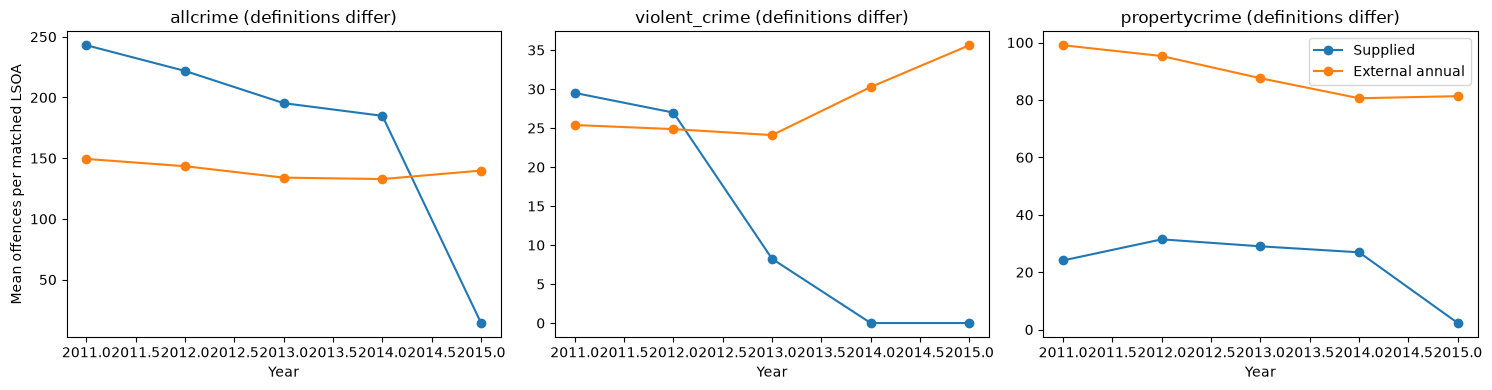

In [65]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (supplied, ext) in zip(axes, PAIRS.items()):
    b = pd.DataFrame(compare).loc[lambda x: x.supplied.eq(supplied) & x.lsoa_years.gt(0)]
    ax.plot(b.year, b.supplied_mean, 'o-', label='Supplied')
    ax.plot(b.year, b.external_mean, 'o-', label='External annual')
    ax.set_title(supplied + ' (definitions differ)')
    ax.set_xlabel('Year')
axes[0].set_ylabel('Mean offences per matched LSOA')
axes[-1].legend()
fig.tight_layout()
fig.savefig(OUT / 'crime_measurement_comparison.png', dpi=160)
plt.show()

### 3.9 Build an identical annual/prior regression sample

Use the external source for both timings to hold offence definitions fixed. Omit job density to retain 2015. All three main categories and both timings share a sample; M6 and M7 use the same controls and fixed effects as above.

In [66]:
enriched = merged.copy()
enriched['lnprice'] = np.log(enriched.price.where(enriched.price.gt(0)))
enriched['newbuild'] = enriched.age.eq('Y').astype(float)
enriched['borough_year'] = enriched.oslaua + '_' + enriched.year.astype(str)
for name in ['tube_distnear', 'bus_distnear', 'thamesriv_dist', 'Nearest_Park_dist']:
    enriched[name + '_km'] = enriched[name] / 1000
enriched['lnpay'] = np.log(enriched.grossannualpay.where(enriched.grossannualpay.gt(0)))
MAIN = ['mps_all', 'mps_violence', 'mps_property']
timing_columns = []
for c in MAIN:
    for timing in ['annual', 'prior12']:
        reg = 'log1p_' + c + '_' + timing
        enriched[reg] = np.log1p(enriched[c + '_' + timing])
        timing_columns.append(reg)
paired = common_sample(enriched, include_jobdensity=False, crime_cols=timing_columns)
assert paired.year.ge(2011).all()
assert paired.transactiondates.ge(pd.Timestamp('2011-04-01')).all()
print('Identical annual/prior regression sample:', len(paired), 'transactions;', paired.lsoacode.nunique(), 'LSOAs')
table(paired.groupby('year').size().to_frame('N'), 'regression_sample_by_year')
table(paired[timing_columns].describe().T, 'regression_crime_distributions')

Identical annual/prior regression sample: 405088 transactions; 4648 LSOAs


,N
year,
2011,66741
2012,85375
2013,99429
2014,108207
2015,45336


,count,mean,std,min,25%,50%,75%,max
log1p_mps_all_annual,405088.0,4.6964,0.6633,2.4849,4.2767,4.6347,5.0370,8.9082
log1p_mps_all_prior12,405088.0,4.7019,0.6634,2.3026,4.2767,4.6444,5.0434,8.9150
log1p_mps_violence_annual,405088.0,3.0239,0.7593,0.0000,2.5649,3.0445,3.5264,6.8512
log1p_mps_violence_prior12,405088.0,2.9773,0.7591,0.0000,2.4849,2.9957,3.4657,6.8814
log1p_mps_property_annual,405088.0,4.2618,0.6704,2.0794,3.8286,4.1897,4.5850,8.4805
log1p_mps_property_prior12,405088.0,4.2848,0.6676,1.7918,3.8501,4.2195,4.6052,8.4933


### 3.10 Estimate M6 and M7 for annual and prior exposure

In [67]:
results = []
coefficients = []
for model, controls, effects in specifications(False)[-2:]:
    print('Estimating', model, flush=True)
    columns = ['lnprice'] + timing_columns + controls
    matrix = paired[columns].to_numpy(dtype=float, copy=True)
    scale = matrix.std(axis=0)
    scale[scale < 1e-14] = 1
    projected, iterations = absorb(matrix / scale, [paired[c] for c in effects])
    projected[:, projected.std(axis=0) < 1e-07] = 0
    transformed = paired.copy()
    transformed[columns] = projected * scale
    for measure in MAIN:
        for timing in ['annual', 'prior12']:
            reg = 'log1p_' + measure + '_' + timing
            r, b = fit_absorbed(transformed, reg, controls, [])
            r.update(fixed_effects='; '.join(effects), r2_type='within', iterations=iterations)
            results.append(dict(model=model, measure=measure, timing=timing, **r))
            coefficients.append(b.assign(model=model, measure=measure, timing=timing))
results = pd.DataFrame(results)
pd.concat(coefficients).to_csv(OUT / 'external_timing_all_coefficients.csv', index=False)
timing_coefficients = show_models(results, 'external_timing_regressions', 'external_timing_all_coefficients.csv')

Estimating M6
Estimating M7


Variable,Coefficient,Clustered SE,t statistic,95% CI,p-value
Crime: log(1 + mps all annual),0.0068,0.0047,1.45,-0.0024 to 0.0160,0.147
Detached (relative to flat),0.6011,0.0127,47.31,0.5762 to 0.6260,<0.001
Semi-detached (relative to flat),0.3258,0.0112,29.20,0.3040 to 0.3477,<0.001
Terraced (relative to flat),0.1987,0.0109,18.19,0.1773 to 0.2201,<0.001
Freehold,0.4084,0.0108,37.95,0.3873 to 0.4295,<0.001
New build,0.1955,0.0090,21.64,0.1778 to 0.2132,<0.001
Distance to tube station (km),0.0045,0.0123,0.37,-0.0195 to 0.0285,0.715
Distance to bus stop (km),0.1572,0.0234,6.70,0.1112 to 0.2031,<0.001
Distance to Thames (km),0.0020,0.0139,0.14,-0.0253 to 0.0292,0.888
Distance to park (km),-0.0285,0.0157,-1.82,-0.0594 to 0.0023,0.070


### 3.11 Plot the timing comparison

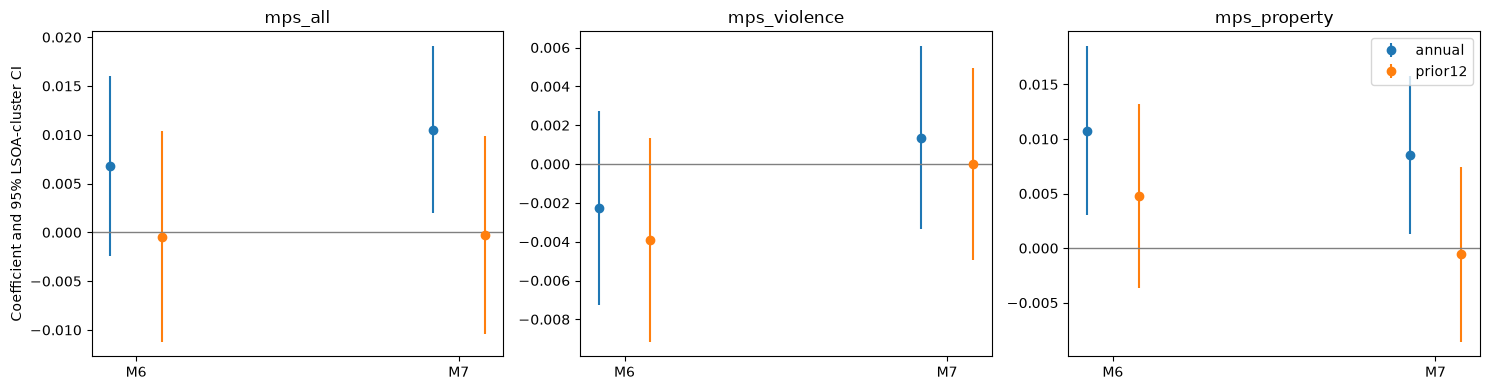

In [68]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, measure in zip(axes, MAIN):
    for timing, offset in [('annual', -0.08), ('prior12', 0.08)]:
        b = results.loc[results.measure.eq(measure) & results.timing.eq(timing)]
        ax.errorbar(np.arange(2) + offset, b.beta, yerr=np.vstack([b.beta - b.ci_low, b.ci_high - b.beta]), fmt='o', label=timing)
    ax.set_xticks([0, 1], ['M6', 'M7'])
    ax.set_title(measure)
    ax.axhline(0, color='grey', linewidth=1)
axes[0].set_ylabel('Coefficient and 95% LSOA-cluster CI')
axes[-1].legend()
fig.tight_layout()
fig.savefig(OUT / 'annual_vs_prior12_coefficients.png', dpi=160)
plt.show()

### 3.12 Assess selection into the matched sample

In [69]:
enriched['in_timing_sample'] = enriched.transaction_id.isin(paired.transaction_id)
eligible = enriched.loc[enriched.transactiondates.ge(pd.Timestamp('2011-04-01')) & enriched.oslaua.str.startswith('E090')]
selection = eligible.groupby('in_timing_sample').agg(N=('price', 'size'), median_price=('price', 'median'), mean_price=('price', 'mean'), flat_share=('flat_dum', 'mean'), newbuild_share=('newbuild', 'mean'), lsoas=('lsoacode', 'nunique'))
table(selection, 'included_vs_excluded_transactions')
preferred = results.loc[results.model.eq('M7') & results.timing.eq('prior12')]
table(preferred[['measure', 'N', 'clusters', 'beta', 'se', 'ci_low', 'ci_high', 'p', 'crime_residual_sd']], 'preferred_prior12_summary')
print('M7 prior12 confidence intervals include zero:', dict(zip(preferred.measure, preferred.ci_low.le(0) & preferred.ci_high.ge(0))))
print('Main outputs are in', OUT)
print('Merged data: land_registry_crime_monthly_merged.csv.gz')
print('No original input file has been modified.')

,N,median_price,mean_price,flat_share,newbuild_share,lsoas
in_timing_sample,,,,,,
False,35418,312000.0,432725.7237,0.8116,0.3935,326
True,405088,333500.0,480617.0637,0.5095,0.0647,4648


,measure,N,clusters,beta,se,ci_low,ci_high,p,crime_residual_sd
7,mps_all,405088,4648,-2.4882e-04,0.0052,-0.0104,0.0099,0.9617,0.1326
9,mps_violence,405088,4648,6.2543e-06,0.0025,-0.0049,0.0049,0.9980,0.2590
11,mps_property,405088,4648,-5.7614e-04,0.0041,-0.0086,0.0074,0.8875,0.1573


M7 prior12 confidence intervals include zero: {'mps_all': True, 'mps_violence': True, 'mps_property': True}
Main outputs are in c:\Users\rachm\OneDrive - Nanyang Technological University\Syllabus\Y4S1\HE3027\project\project_data\crime_outputs
Merged data: land_registry_crime_monthly_merged.csv.gz
No original input file has been modified.


## 4. Interpretation and next decision

Read coefficient movements alongside confidence intervals, residual crime variation, source warnings and sample coverage. LSOA effects absorb persistent neighbourhood differences; borough-year effects absorb shared borough-year shocks. Neither addresses all local changes in housing quality, regeneration or reverse causality.

A significant annual estimate and an insignificant prior estimate do not establish a statistically significant difference between them; that requires a joint test. Insignificance does not establish that crime has no effect. Prior recorded crime also need not equal information buyers possessed when negotiating prices.

All outputs are in `OUT` (the input folder's `crime_outputs/` subfolder), including the merged `.csv.gz`. Use valid LSOA population/area data before calculating rates or densities. Choose one further extension only after reviewing these results.

## 5. Display all saved regression tables

This optional cell belongs at the end: it reads the result files saved by the preceding analysis and does not estimate any regressions. Each expandable table includes the crime and control coefficients. To display previously saved results in a fresh session, run the setup and output-helper cells first, then this cell.

M7 absorbs borough-year economic controls, so they have no separate coefficients. Fixed-effect intercepts are not reported; the demeaning estimator also does not report the constant in M1?M4.


In [56]:
panels_to_display = [
    ('Strict sample', 'strict_models.csv', 'strict_all_coefficients.csv'),
    ('Without job density', 'without_jobdensity_models.csv', 'without_jobdensity_all_coefficients.csv'),
    ('Monthly crime timing', 'external_timing_regressions.csv', 'external_timing_all_coefficients.csv'),
]
for label, model_file, coefficient_file in panels_to_display:
    if (OUT / model_file).is_file() and (OUT / coefficient_file).is_file():
        from IPython.display import HTML
        display(HTML('<h3>' + label + '</h3>'))
        show_models(pd.read_csv(OUT / model_file), Path(model_file).stem, coefficient_file)
    else:
        print(label + ': saved result files not found in ' + str(OUT))

Variable,Coefficient,Clustered SE,t statistic,95% CI,p-value
Crime: log(1 + allcrime),0.0193,0.0048,3.99,0.0098 to 0.0288,<0.001
Variable,Coefficient,Clustered SE,t statistic,95% CI,p-value
Crime: log(1 + violent crime),-0.0641,0.0026,-24.67,-0.0692 to -0.0590,<0.001
Variable,Coefficient,Clustered SE,t statistic,95% CI,p-value
Crime: log(1 + propertycrime),0.0249,0.0037,6.80,0.0177 to 0.0321,<0.001
Variable,Coefficient,Clustered SE,t statistic,95% CI,p-value
Crime: log(1 + allcrime),0.0448,0.0048,9.28,0.0354 to 0.0543,<0.001
Detached (relative to flat),0.6293,0.0233,27.04,0.5837 to 0.6749,<0.001
Semi-detached (relative to flat),0.1559,0.0185,8.43,0.1196 to 0.1921,<0.001
Terraced (relative to flat),0.1138,0.0177,6.44,0.0791 to 0.1484,<0.001


Variable,Coefficient,Clustered SE,t statistic,95% CI,p-value
Crime: log(1 + allcrime),-0.0051,0.0040,-1.28,-0.0130 to 0.0027,0.201
Variable,Coefficient,Clustered SE,t statistic,95% CI,p-value
Crime: log(1 + violent crime),-0.0692,0.0023,-29.54,-0.0738 to -0.0646,<0.001
Variable,Coefficient,Clustered SE,t statistic,95% CI,p-value
Crime: log(1 + propertycrime),0.0003,0.0031,0.10,-0.0058 to 0.0064,0.922
Variable,Coefficient,Clustered SE,t statistic,95% CI,p-value
Crime: log(1 + allcrime),0.0147,0.0040,3.71,0.0069 to 0.0224,<0.001
Detached (relative to flat),0.6144,0.0231,26.65,0.5692 to 0.6596,<0.001
Semi-detached (relative to flat),0.1500,0.0182,8.23,0.1143 to 0.1858,<0.001
Terraced (relative to flat),0.1158,0.0174,6.66,0.0817 to 0.1499,<0.001


Variable,Coefficient,Clustered SE,t statistic,95% CI,p-value
Crime: log(1 + mps all annual),0.0068,0.0047,1.45,-0.0024 to 0.0160,0.147
Detached (relative to flat),0.6011,0.0127,47.31,0.5762 to 0.6260,<0.001
Semi-detached (relative to flat),0.3258,0.0112,29.20,0.3040 to 0.3477,<0.001
Terraced (relative to flat),0.1987,0.0109,18.19,0.1773 to 0.2201,<0.001
Freehold,0.4084,0.0108,37.95,0.3873 to 0.4295,<0.001
New build,0.1955,0.0090,21.64,0.1778 to 0.2132,<0.001
Distance to tube station (km),0.0045,0.0123,0.37,-0.0195 to 0.0285,0.715
Distance to bus stop (km),0.1572,0.0234,6.70,0.1112 to 0.2031,<0.001
Distance to Thames (km),0.0020,0.0139,0.14,-0.0253 to 0.0292,0.888
Distance to park (km),-0.0285,0.0157,-1.82,-0.0594 to 0.0023,0.070
